# DSA2050 (WK6) – Guided Regression Lab
## Regression and Baseline Comparison

**Student name:** Tamara Mwakisha  
**Student ID:** 660146  
**Dataset:** `DSA2050_Week6_Sales_Data.csv`

Using sales activity and business attributes as inputs, this notebook creates a predictive model for sales revenue, expressed in Kenyan shillings. After establishing the mean and median baselines, a shallow Decision Tree, Ridge Regression, and Linear Regression are compared. To ensure that model selection is independent of the test set, 20% of the data is set aside as a test set, and only the training data is subjected to 5-fold cross-validation. To evaluate overfitting, the research looks at residuals, error variance across subgroups, and the difference between training and test performance in addition to headline performance indicators. In an extension, the impact of model complexity on generalization is assessed by varying tree depth.

> Run all cells from top to bottom. Set the CSV path below if the data file is not beside this notebook.

## 1. Imports and reproducibility

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

## 2. Load data and define the task

In [2]:
df = pd.read_csv('DSA2050_Week6_Sales_Data.csv')
display(df.head())
print('Shape:', df.shape)
df.info()

,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,Sales_KES
0,10801,326,17,Nairobi,SME,Electronics,152376
1,55307,162,23,Nairobi,Retail,Home,119137
2,47547,553,22,Mombasa,Corporate,Office,219441
3,33527,785,12,Nairobi,SME,Electronics,234210
4,33145,830,20,Nairobi,Retail,Home,204277


Shape: (320, 7)
<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   AdvertisingSpend_KES  320 non-null    int64
 1   StoreVisits           320 non-null    int64
 2   DiscountPercent       320 non-null    int64
 3   Region                320 non-null    str  
 4   CustomerSegment       320 non-null    str  
 5   ProductCategory       320 non-null    str  
 6   Sales_KES             320 non-null    int64
dtypes: int64(4), str(3)
memory usage: 17.6 KB


This dataset contains 320 records, where each record represents an individual sales event, and it has seven attributes in total: six predictor features and one continuous target variable, sales revenue in Kenyan shillings. Three of the predictors are numeric (`AdvertisingSpend_KES`, `StoreVisits`, and `DiscountPercent`), while the other three are categorical (`Region`, `CustomerSegment`, and `ProductCategory`). Since the target is continuous and the data includes labeled outcomes, this is a supervised regression problem, where the goal is to estimate sales revenue from a combination of operational metrics and categorical descriptors.

## 3. Basic data audit

Missing values by column:


,Missing
AdvertisingSpend_KES,0
StoreVisits,0
DiscountPercent,0
Region,0
CustomerSegment,0
ProductCategory,0
Sales_KES,0


Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
AdvertisingSpend_KES,320.00,NaN,NaN,NaN,"37,421.78","17,745.83","5,478.00","22,985.50","37,144.00","52,307.75","69,746.00"
StoreVisits,320.00,NaN,NaN,NaN,465.44,231.65,84.00,262.00,461.50,685.50,848.00
DiscountPercent,320.00,NaN,NaN,NaN,12.81,7.72,0.00,6.00,13.50,20.00,25.00
Region,320,4,Nairobi,139,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CustomerSegment,320,3,Retail,157,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ProductCategory,320,4,Electronics,95,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sales_KES,320.00,NaN,NaN,NaN,"169,252.45","51,968.08","17,805.00","131,448.75","168,462.00","207,050.75","295,825.00"


,Sales_KES
count,320.00
mean,"169,252.45"
std,"51,968.08"
min,"17,805.00"
25%,"131,448.75"
50%,"168,462.00"
75%,"207,050.75"
max,"295,825.00"


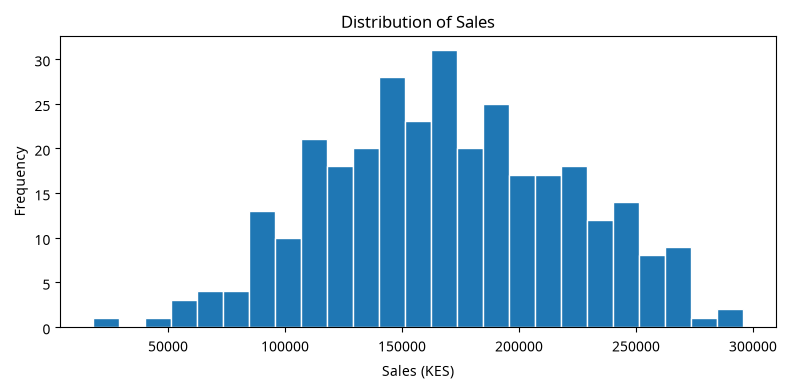

In [3]:
print('Missing values by column:')
display(df.isna().sum().to_frame('Missing'))
print('Duplicate rows:', df.duplicated().sum())
display(df.describe(include='all').T)
display(df['Sales_KES'].describe().to_frame('Sales_KES'))

plt.figure(figsize=(8, 4))
plt.hist(df['Sales_KES'], bins=25, edgecolor='white')
plt.title('Distribution of Sales')
plt.xlabel('Sales (KES)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

The target variable ranges widely, from KES 17,805 to KES 295,825. Its average value is approximately KES 169,252, while the median is KES 168,462; the close agreement between these two measures suggests that the overall distribution is fairly symmetrical rather than strongly skewed. Nevertheless, a histogram should still be examined to identify possible multiple peaks or unusually heavy tails. Although the highest and lowest values appear distant from the central values, they were deliberately retained, since observations should not be removed unless there is clear evidence that they resulted from an error or data corruption.

## 4. Features, target and train/test split

In [4]:
target = 'Sales_KES'
X = df.drop(columns=target)
y = df[target]
print('X shape:', X.shape, '| y shape:', y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print('Training rows:', len(X_train))
print('Test rows:', len(X_test))

numeric_features = ['AdvertisingSpend_KES', 'StoreVisits', 'DiscountPercent']
categorical_features = ['Region', 'CustomerSegment', 'ProductCategory']

X shape: (320, 6) | y shape: (320,)
Training rows: 256
Test rows: 64


## 5. Leakage-safe preprocessing and model definitions

In [5]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

models = {
    'Mean Baseline': DummyRegressor(strategy='mean'),
    'Median Baseline': DummyRegressor(strategy='median'),
    'Linear Regression': Pipeline([('preprocess', preprocessor), ('model', LinearRegression())]),
    'Ridge Regression': Pipeline([('preprocess', preprocessor), ('model', Ridge(alpha=1.0))]),
    'Decision Tree': Pipeline([('preprocess', preprocessor), ('model', DecisionTreeRegressor(
        max_depth=4, min_samples_leaf=8, random_state=RANDOM_STATE))])
}

def evaluate_regression(y_true, y_pred, name):
    return {'Model': name,
            'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred)}

## 6. Fit and compare baselines and candidate models

In [6]:
test_predictions = {}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    test_predictions[name] = prediction
    rows.append(evaluate_regression(y_test, prediction, name))

comparison = pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)
display(comparison)

,Model,MAE,RMSE,R2
0,Ridge Regression,"13,714.40","17,458.82",0.87
1,Linear Regression,"13,757.84","17,469.69",0.87
2,Decision Tree,"23,775.92","28,767.64",0.65
3,Median Baseline,"39,146.75","48,649.47",-0.01
4,Mean Baseline,"39,197.16","48,716.43",-0.01


**Test-set interpretation.** The median baseline is the stronger baseline on this split (MAE **KES 39,147**, versus **KES 39,197** for the mean baseline). Ridge Regression has the lowest MAE (**KES 13,714**) and RMSE (**KES 17,459**) and the highest R² (**0.8705**) among these models, only narrowly ahead of ordinary Linear Regression (MAE **KES 13,758**, R² **0.8703**). Both linear models substantially beat the baseline on this holdout. One test table is not sufficient for a final conclusion because it is based on one split; cross-validation and diagnostics help assess stability, and model choice should also account for intended use and error consequences.

## 7. Cross-validation on training data only

In [7]:
scoring = {'MAE': 'neg_mean_absolute_error',
           'RMSE': 'neg_root_mean_squared_error',
           'R2': 'r2'}
cv_rows = []
for name in ['Linear Regression', 'Ridge Regression', 'Decision Tree']:
    scores = cross_validate(models[name], X_train, y_train, cv=5, scoring=scoring)
    cv_rows.append({
        'Model': name,
        'CV_MAE': -scores['test_MAE'].mean(),
        'CV_RMSE': -scores['test_RMSE'].mean(),
        'CV_R2': scores['test_R2'].mean()
    })
cv_results = pd.DataFrame(cv_rows).sort_values('CV_MAE').reset_index(drop=True)
display(cv_results)

,Model,CV_MAE,CV_RMSE,CV_R2
0,Ridge Regression,"15,971.37","20,103.54",0.85
1,Linear Regression,"15,976.77","20,126.77",0.85
2,Decision Tree,"24,498.47","30,608.68",0.65


Ridge has the lowest average CV MAE (about **KES 15,971**) and RMSE (about **KES 20,104**), with average R² about **0.848**; Linear Regression is virtually tied (CV MAE about **KES 15,977**). The Decision Tree is worse on average (CV MAE about **KES 24,498**). These results broadly agree with the test-set ranking: Ridge/Linear lead, followed by the tree. Cross-validation uses only training data to compare model behaviour across folds, preserving the test set as a less biased final check rather than repeatedly tuning to it.

## 8. Residual analysis for Linear Regression

,Actual,Predicted,Residual
167,149359,"136,532.31","12,826.69"
230,198924,"196,021.09","2,902.91"
25,152671,"143,638.94","9,032.06"
63,133621,"172,495.44","-38,874.44"
9,171171,"149,069.70","22,101.30"


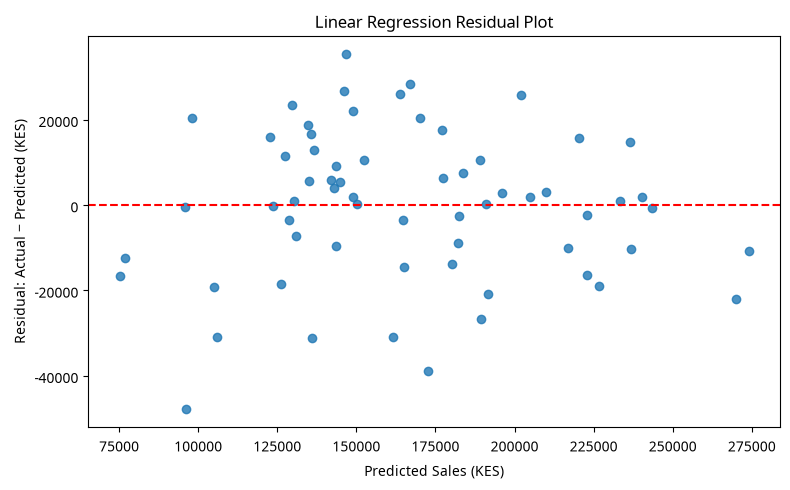

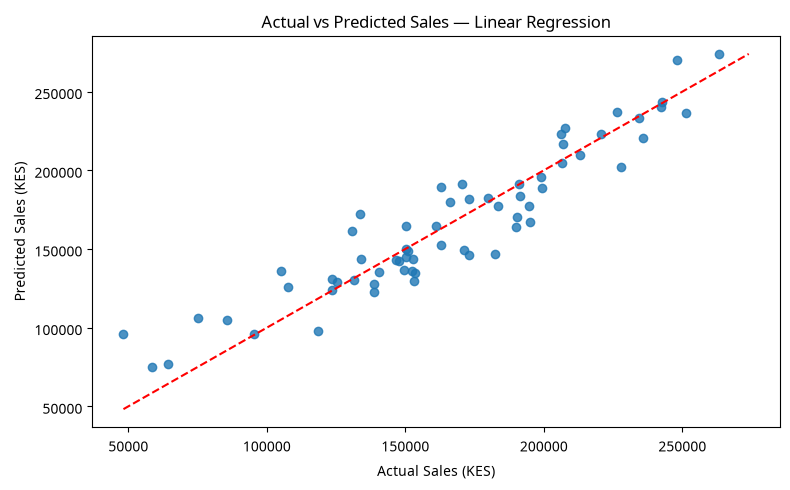

Residual mean: -337.2539743144089 | median: 976.9476716091667 | min: -47859.85465735296 | max: 35378.884060440614


In [8]:
linear_pred = test_predictions['Linear Regression']
residuals = y_test.to_numpy() - linear_pred
residual_df = pd.DataFrame({
    'Actual': y_test.to_numpy(),
    'Predicted': linear_pred,
    'Residual': residuals
}, index=y_test.index)
display(residual_df.head())

plt.figure(figsize=(8, 5))
plt.scatter(linear_pred, residuals, alpha=0.8)
plt.axhline(0, color='red', linestyle='--')
plt.title('Linear Regression Residual Plot')
plt.xlabel('Predicted Sales (KES)')
plt.ylabel('Residual: Actual − Predicted (KES)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(y_test, linear_pred, alpha=0.8)
lims = [min(y_test.min(), linear_pred.min()), max(y_test.max(), linear_pred.max())]
plt.plot(lims, lims, 'r--')
plt.title('Actual vs Predicted Sales — Linear Regression')
plt.xlabel('Actual Sales (KES)')
plt.ylabel('Predicted Sales (KES)')
plt.tight_layout()
plt.show()
print('Residual mean:', residuals.mean(), '| median:', np.median(residuals),
      '| min:', residuals.min(), '| max:', residuals.max())

Residuals are centred close to zero (mean approximately **−KES 337**), with both under-predictions (positive residuals) and over-predictions (negative residuals). The residual plot and actual-versus-predicted plot should be read for curvature, changing spread, or systematic departures from the diagonal; individual errors are substantial, reaching roughly **−KES 47,860** and **+KES 35,379**. This is a useful fit, not a claim that every transaction is predicted closely.

## 9. Largest absolute errors and segment-level performance

In [9]:
error_analysis = X_test.copy()
error_analysis['ActualSales'] = y_test
error_analysis['PredictedSales'] = linear_pred
error_analysis['Residual'] = y_test - linear_pred
error_analysis['AbsoluteError'] = error_analysis['Residual'].abs()
display(error_analysis.sort_values('AbsoluteError', ascending=False).head(10))

segment_errors = (error_analysis.groupby('CustomerSegment')
    .agg(Observations=('AbsoluteError', 'size'),
         MAE=('AbsoluteError', 'mean'))
    .reset_index().sort_values('MAE', ascending=False))
display(segment_errors)

,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,ActualSales,PredictedSales,Residual,AbsoluteError
139,33386,161,22,Nairobi,Retail,Home,48229,"96,088.85","-47,859.85","47,859.85"
63,67888,265,4,Nakuru,SME,Accessories,133621,"172,495.44","-38,874.44","38,874.44"
46,33969,441,10,Nakuru,Retail,Accessories,182186,"146,807.12","35,378.88","35,378.88"
7,50328,108,13,Nairobi,Retail,Electronics,104994,"136,091.95","-31,097.95","31,097.95"
5,60808,257,8,Nairobi,Retail,Accessories,130757,"161,701.20","-30,944.20","30,944.20"
76,26462,114,13,Nairobi,Retail,Electronics,75103,"106,000.27","-30,897.27","30,897.27"
260,56576,151,0,Nairobi,Corporate,Home,195145,"166,919.22","28,225.78","28,225.78"
226,57562,410,21,Kisumu,Corporate,Office,162770,"189,424.02","-26,654.02","26,654.02"
73,13444,541,19,Nakuru,Retail,Electronics,172866,"146,216.70","26,649.30","26,649.30"
297,33529,285,3,Nairobi,Corporate,Office,189884,"163,816.77","26,067.23","26,067.23"


,CustomerSegment,Observations,MAE
1,Retail,27,"15,560.58"
0,Corporate,19,"14,300.00"
2,SME,18,"10,481.46"


On the Linear Regression test errors, Retail has the highest segment MAE (about **KES 15,561**), followed by Corporate (**KES 14,300**) and SME (**KES 10,481**). Test sample counts (27 Retail, 19 Corporate, 18 SME) are reasonably similar but small, so subgroup rankings are descriptive and uncertain. The largest-error records span multiple regions, segments and categories rather than being confined to one obvious group; the most extreme is an underprediction in a Nairobi/Retail/Home observation. More detailed temporal, store-level, campaign, inventory, transaction-mix and customer information could explain such cases. Subgroup checks matter because acceptable overall error can conceal unequal reliability for a particular customer group.

## 10. Overfitting check: shallow and unrestricted trees

In [10]:
tree_model = models['Decision Tree']
tree_test_pred = test_predictions['Decision Tree']
print('Shallow tree training MAE:', mean_absolute_error(y_train, tree_model.predict(X_train)))
print('Shallow tree test MAE:', mean_absolute_error(y_test, tree_test_pred))

deep_tree = Pipeline([
    ('preprocess', preprocessor),
    ('model', DecisionTreeRegressor(random_state=RANDOM_STATE))
])
deep_tree.fit(X_train, y_train)
print('Unrestricted tree training MAE:', mean_absolute_error(y_train, deep_tree.predict(X_train)))
print('Unrestricted tree test MAE:', mean_absolute_error(y_test, deep_tree.predict(X_test)))

Shallow tree training MAE: 18029.702603600923
Shallow tree test MAE: 23775.924940229997
Unrestricted tree training MAE: 0.0
Unrestricted tree test MAE: 26797.5


The unrestricted tree attains **zero training MAE** but test MAE around **KES 26,798**, far worse than the shallow tree’s test MAE around **KES 23,776**. The near-perfect training score reflects memorization/overfitting rather than reliable generalization. Even the shallow tree has a train/test gap, although it is less extreme.

## 11. Extension: compare tree depth values

In [11]:
depth_rows = []
for depth in [2, 4, 6, None]:
    candidate = Pipeline([
        ('preprocess', preprocessor),
        ('model', DecisionTreeRegressor(max_depth=depth, min_samples_leaf=8,
                                        random_state=RANDOM_STATE))
    ])
    candidate.fit(X_train, y_train)
    depth_rows.append({
        'max_depth': str(depth),
        'Test_MAE': mean_absolute_error(y_test, candidate.predict(X_test))
    })
depth_results = pd.DataFrame(depth_rows).sort_values('Test_MAE')
display(depth_results)

,max_depth,Test_MAE
3,None,"22,747.38"
2,6,"23,436.02"
1,4,"23,775.92"
0,2,"27,354.30"


Among the specified depth choices with `min_samples_leaf=8`, depth 6 yields the lowest test MAE on this split (about **KES 23,436**), narrowly improving on depth 4. This is a one-split extension comparison, not evidence to deploy a tree: the linear models remain substantially better, and selecting the depth on the test set would consume test information. In a full selection workflow, depth would be chosen using training-only cross-validation and the final test set evaluated once.

## 12. Final recommendation

The median dummy regressor is the strongest baseline on the held-out test set, with MAE of about KES 39,147. Ridge Regression is the best candidate overall on that set, with MAE about KES 13,714, RMSE about KES 17,459, and R² about 0.870; its cross-validation result is also marginally best and almost tied with Linear Regression. It clearly improves on the baseline in this dataset, reducing the average absolute error by roughly KES 25,432 per observation relative to the median baseline. In business terms, MAE is the average magnitude by which a prediction differs from realized sales, regardless of direction. Linear-model residuals are approximately centred, but several individual errors are large and should be investigated. Retail shows the highest segment MAE while SME is lowest, with modest segment sample sizes. The unrestricted tree’s zero training error but much worse test error is strong evidence of overfitting. I would not deploy immediately: first validate on newer, representative data, investigate major errors, monitor segment fairness and drift, and confirm that the prediction timing and business use are appropriate.

## 13. Limitations

1. The dataset is modest in size (320 rows), so both the holdout and subgroup samples are limited and estimates may vary across new samples.
2. Only six predictors are available; seasonality, store characteristics, product pricing, stock availability, campaign details, and economic conditions may be missing.
3. The source and representativeness of the data are not established here; it may not reflect future operations or all sales contexts.
4. Performance can drift as customer behaviour, prices, promotions, or markets change, requiring temporal validation and monitoring.
5. Predictive associations do not show that advertising, discounts, or visits cause sales; this model is not a causal analysis.

## Submission checklist